<a href="https://colab.research.google.com/github/Om2O4/EDA-Sem-V/blob/main/eda_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [11]:
!pip install -q ydata-profiling
!pip install --force-reinstall -q "numpy<2.3" ydata-profiling

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires ipykernel==6.17.1, but you have ipykernel 7.4.0 which is incompatible.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 2.3.3 which is incompatible.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.
google-cloud-bigquery 3.47.0 requires python-dateutil<3.0.0,>=2.8.2, but you have python-dateutil 4.0.0 which is incompatible.
notebook 6.5.7 requires jupyter-client<8,>=5.3.4, but you have jupyter-client 8.10.0 which is incompatible.
gradio 6.31.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.
bigframes 2.51.0 requires python-dateutil<3,>=2.8.2, but you have python-dateutil 4.0.0 which is incompatible.
betterproto 2.0.0b7 requires python-dateutil<3.0,>=2.8, but you have python-dateutil 4.0.0 which i

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load dataset and immediately treat "Not Available" and blanks as NaN
df_raw = pd.read_csv(
    "/content/Energy_and_Water_Data_Disclosure_for_Local_Law_84_2022__Data_for_Calendar_Year_2021_.csv",
    na_values=["Not Available", "not available", "N/A", ""],
    low_memory=False
)

# 2. Helper function to match columns cleanly regardless of minor symbol differences
def find_col(df, keyword):
    matches = [c for c in df.columns if keyword.lower() in c.lower()]
    return matches[0] if matches else None

col_map = {
    find_col(df_raw, "Borough"): "Borough",
    find_col(df_raw, "Primary Property Type - Self Selected"): "Primary_Property_Type",
    find_col(df_raw, "Year Built"): "Year_Built",
    find_col(df_raw, "Property GFA - Calculated (Buildings)"): "Property_GFA",
    find_col(df_raw, "ENERGY STAR Score"): "ENERGY_STAR_Score",
    find_col(df_raw, "Site EUI (kBtu/ft"): "Site_EUI",
    find_col(df_raw, "Weather Normalized Site Electricity (kWh)"): "Weather_Norm_Electricity",
    find_col(df_raw, "Natural Gas Use (kBtu)"): "Natural_Gas_Use",
    find_col(df_raw, "Total GHG Emissions (Metric Tons CO2e)"): "Total_GHG_Emissions",
    find_col(df_raw, "Postcode"): "Postcode"
}

# Keep only mapped key columns (drop None keys if any)
valid_map = {k: v for k, v in col_map.items() if k is not None}
df = df_raw[list(valid_map.keys())].rename(columns=valid_map)

# 3. Enforce numeric data types on numerical features
num_cols = [
    "Year_Built", "Property_GFA", "ENERGY_STAR_Score",
    "Site_EUI", "Weather_Norm_Electricity", "Natural_Gas_Use", "Total_GHG_Emissions"
]
for col in num_cols:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

print(f"Dataset Shape: {df.shape}")
df.head()

Dataset Shape: (29842, 9)


,Borough,Primary_Property_Type,Year_Built,Property_GFA,ENERGY_STAR_Score,Site_EUI,Weather_Norm_Electricity,Natural_Gas_Use,Total_GHG_Emissions
0,4006520042,Multifamily Housing,2010,25000.0,71.0,66.7,173893.6,1062527.9,107.5
1,1-01206-0001,Multifamily Housing,1970,261980.0,100.0,19.2,1229531.2,827319.8,398.6
2,1-01832-0043,Multifamily Housing,1943,333342.0,84.0,66.9,1283733.2,17935807.7,1323.0
3,1-00142-0025,Multifamily Housing,1975,1112900.0,3.0,113.8,7490754.3,99284398.0,7582.1
4,4-09649-0053,Multifamily Housing,1953,87020.0,37.0,102.1,370028.2,7324199.9,518.3


In [8]:
!pip install -q skimpy
from skimpy import skim

skim(df)

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires ipykernel==6.17.1, but you have ipykernel 7.4.0 which is incompatible.
notebook 6.5.7 requires jupyter-client<8,>=5.3.4, but you have jupyter-client 8.10.0 which is incompatible.
jupyter-kernel-gateway 2.5.2 requires jupyter_client<8.0,>=5.2.0, but you have jupyter-client 8.10.0 which is incompatible.


╭──────────────────────────────────────────────── skimpy summary ─────────────────────────────────────────────────╮
│          Data Summary                Data Types                                                                 │
│ ┏━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┓ ┏━━━━━━━━━━━━━┳━━━━━━━┓                                                          │
│ ┃ Dataframe         ┃ Values ┃ ┃ Column Type ┃ Count ┃                                                          │
│ ┡━━━━━━━━━━━━━━━━━━━╇━━━━━━━━┩ ┡━━━━━━━━━━━━━╇━━━━━━━┩                                                          │
│ │ Number of rows    │ 29842  │ │ float64     │ 6     │                                                          │
│ │ Number of columns │ 9      │ │ string      │ 2     │                                                          │
│ └───────────────────┴────────┘ │ int64       │ 1     │                                                          │
│                                └─────────────┴───────┘                                                          │
│                                                     number                                                      │
│ ┏━━━━━━━━━━━┳━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━┳━━━━━━┳━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━┓  │
│ ┃ column    ┃ NA   ┃ NA %      ┃ mean    ┃ sd       ┃ p0   ┃ p25    ┃ p50     ┃ p75     ┃ p100      ┃ hist   ┃  │
│ ┡━━━━━━━━━━━╇━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━╇━━━━━━╇━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━┩  │
│ │ Year_Buil │    0 │         0 │    1950 │    34.84 │ 1367 │   1925 │    1940 │    1972 │      2088 │     █▃ │  │
│ │ t         │      │           │         │          │      │        │         │         │           │        │  │
│ │ Property_ │    2 │ 0.0067019 │  124300 │   312800 │    1 │  36900 │   60350 │  114000 │  21150000 │   █    │  │
│ │ GFA       │      │ 636753568 │         │          │      │        │         │         │           │        │  │
│ │           │      │         8 │         │          │      │        │         │         │           │        │  │
│ │ ENERGY_ST │ 6824 │ 22.867100 │   59.58 │    29.48 │    1 │     37 │      64 │      85 │       100 │ ▄▃▄▅▆█ │  │
│ │ AR_Score  │      │  06031767 │         │          │      │        │         │         │           │        │  │
│ │ Site_EUI  │ 1981 │ 6.6382950 │     138 │     4822 │    0 │   53.9 │    75.2 │    96.9 │    760100 │   █    │  │
│ │           │      │   2044099 │         │          │      │        │         │         │           │        │  │
│ │ Weather_N │ 2390 │ 8.0088465 │ 1053000 │  3738000 │    0 │ 187300 │  339600 │  752800 │ 206200000 │   █    │  │
│ │ orm_Elect │      │  92051471 │         │          │      │        │         │         │           │        │  │
│ │ ricity    │      │           │         │          │      │        │         │         │           │        │  │
│ │ Natural_G │ 3941 │ 13.206219 │ 6481000 │ 40220000 │    0 │ 709900 │ 2664000 │ 4966000 │ 269400000 │   █    │  │
│ │ as_Use    │      │ 422290731 │         │          │      │        │         │         │         0 │        │  │
│ │ Total_GHG │  618 │ 2.0709067 │    1003 │    35940 │    0 │  150.5 │     276 │   506.7 │   4250000 │   █    │  │
│ │ _Emission │      │  75685276 │         │          │      │        │         │         │           │        │  │
│ │ s         │      │           │         │          │      │        │         │         │           │        │  │
│ └───────────┴──────┴───────────┴─────────┴──────────┴──────┴────────┴─────────┴─────────┴───────────┴────────┘  │
│                                                     string                                                      │
│ ┏━━━━━━━━━━━┳━━━━┳━━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━┓  │
│ ┃           ┃    ┃           ┃          ┃           ┃          ┃           ┃ chars    ┃ words per ┃ total    ┃  │
│ ┃ column    ┃ NA ┃ NA %      ┃ shortest ┃ longest   ┃ 

In [14]:
!pip install --force-reinstall -q "numpy<2.3" ydata-profiling

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires ipykernel==6.17.1, but you have ipykernel 7.4.0 which is incompatible.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 2.3.3 which is incompatible.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.
google-cloud-bigquery 3.47.0 requires python-dateutil<3.0.0,>=2.8.2, but you have python-dateutil 4.0.0 which is incompatible.
notebook 6.5.7 requires jupyter-client<8,>=5.3.4, but you have jupyter-client 8.10.0 which is incompatible.
gradio 6.31.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.
bigframes 2.51.0 requires python-dateutil<3,>=2.8.2, but you have python-dateutil 4.0.0 which is incompatible.
betterproto 2.0.0b7 requires python-dateutil<3.0,>=2.8, but you have python-dateutil 4.0.0 which i

In [16]:
!pip install -q sweetviz

In [17]:
import os
import pandas as pd
import numpy as np
import sweetviz as sv

# 1. Automated HTML Profiling Report (replaces ydata_profiling cleanly in Colab)
# Saves directly to Colab's current directory so you won't get a FileNotFoundError
report = sv.analyze(df)
report.show_html("nyc_ll84_profiling_report.html", open_browser=False)
print("HTML Profiling Report saved as: nyc_ll84_profiling_report.html")

# 2. Custom Statistical Summary Table (for PPT)
summary_rows = []
for col in df.columns:
    missing_pct = round(df[col].isna().mean() * 100, 2)
    dtype = str(df[col].dtype)
    if np.issubdtype(df[col].dtype, np.number):
        skew = round(df[col].skew(), 2)
        q1, q3 = df[col].quantile(0.25), df[col].quantile(0.75)
        iqr = q3 - q1
        outliers = ((df[col] < (q1 - 1.5 * iqr)) | (df[col] > (q3 + 1.5 * iqr))).sum()
    else:
        skew = "N/A"
        outliers = "N/A"
    summary_rows.append({
        "Feature": col,
        "Data_Type": dtype,
        "Missing_%": missing_pct,
        "Skewness": skew,
        "IQR_Outliers": outliers
    })

profiling_summary = pd.DataFrame(summary_rows)
print("\n--- Statistical Summary Table ---")
print(profiling_summary.to_string(index=False))

# Export summary table to CSV so you can easily copy it into PowerPoint
profiling_summary.to_csv("profiling_summary_table.csv", index=False)

                                             |          | [  0%]   00:00 -> (? left)

Report nyc_ll84_profiling_report.html was generated.
HTML Profiling Report saved as: nyc_ll84_profiling_report.html

--- Statistical Summary Table ---
                 Feature Data_Type  Missing_% Skewness IQR_Outliers
                 Borough    object       0.19      N/A          N/A
   Primary_Property_Type    object       0.00      N/A          N/A
              Year_Built     int64       0.00     0.14           56
            Property_GFA   float64       0.01     23.2         2983
       ENERGY_STAR_Score   float64      22.87    -0.41            0
                Site_EUI   float64       6.64   143.11         1364
Weather_Norm_Electricity   float64       8.01    19.56         3271
         Natural_Gas_Use   float64      13.21    33.73         1943
     Total_GHG_Emissions   float64       2.07   114.32         2986


In [ ]:
sns.set_theme(style="whitegrid", palette="viridis")

# --- CHART 1: Borough Distribution ---
plt.figure(figsize=(8, 5))
borough_counts = df["Borough"].value_counts()
sns.barplot(x=borough_counts.index, y=borough_counts.values)
plt.title("Building Count by NYC Borough", fontsize=14, fontweight="bold")
plt.xlabel("Borough")
plt.ylabel("Number of Reported Buildings")
plt.tight_layout()
plt.savefig("../02_EDA_and_Profiling/chart1_borough_dist.png", dpi=300)
plt.show()

# --- CHART 2: Top 10 Primary Property Types ---
plt.figure(figsize=(10, 6))
top_types = df["Primary_Property_Type"].value_counts().head(10)
sns.barplot(y=top_types.index, x=top_types.values)
plt.title("Top 10 Primary Property Types in NYC LL84", fontsize=14, fontweight="bold")
plt.xlabel("Number of Buildings")
plt.ylabel("Property Type")
plt.tight_layout()
plt.savefig("../02_EDA_and_Profiling/chart2_property_types.png", dpi=300)
plt.show()

# --- CHART 3: ENERGY STAR Score Distribution ---
plt.figure(figsize=(8, 5))
sns.histplot(df["ENERGY_STAR_Score"].dropna(), bins=25, kde=True, color="#2b8cbe")
plt.axvline(df["ENERGY_STAR_Score"].median(), color="red", linestyle="--", label=f"Median: {df['ENERGY_STAR_Score'].median():.0f}")
plt.title("Distribution of ENERGY STAR Scores (1–100)", fontsize=14, fontweight="bold")
plt.xlabel("ENERGY STAR Score")
plt.ylabel("Frequency")
plt.legend()
plt.tight_layout()
plt.savefig("../02_EDA_and_Profiling/chart3_energystar_hist.png", dpi=300)
plt.show()

# --- CHART 4: Site EUI Boxplot Across Top 5 Property Types (Outlier View) ---
top5_names = df["Primary_Property_Type"].value_counts().head(5).index
df_top5 = df[df["Primary_Property_Type"].isin(top5_names)]

plt.figure(figsize=(10, 6))
sns.boxplot(data=df_top5, x="Primary_Property_Type", y="Site_EUI", showfliers=False)
plt.title("Site EUI (kBtu/ft²) Spread Across Top 5 Property Types", fontsize=14, fontweight="bold")
plt.xlabel("Primary Property Type")
plt.ylabel("Site EUI (kBtu/ft²)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig("../02_EDA_and_Profiling/chart4_site_eui_boxplot.png", dpi=300)
plt.show()

# --- CHART 5: Total GHG Emissions (Log-Scale Histogram) ---
plt.figure(figsize=(8, 5))
ghg_positive = df[df["Total_GHG_Emissions"] > 0]["Total_GHG_Emissions"]
sns.histplot(np.log10(ghg_positive), bins=30, kde=True, color="#d95f02")
plt.title("Log10 Distribution of Total GHG Emissions (Metric Tons CO2e)", fontsize=14, fontweight="bold")
plt.xlabel("Log10(Total GHG Emissions)")
plt.ylabel("Number of Buildings")
plt.tight_layout()
plt.savefig("../02_EDA_and_Profiling/chart5_ghg_log_hist.png", dpi=300)
plt.show()

/tmp/ipykernel_860/508396398.py:10: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


FileNotFoundError: [Errno 2] No such file or directory: '../02_EDA_and_Profiling/chart1_borough_dist.png'

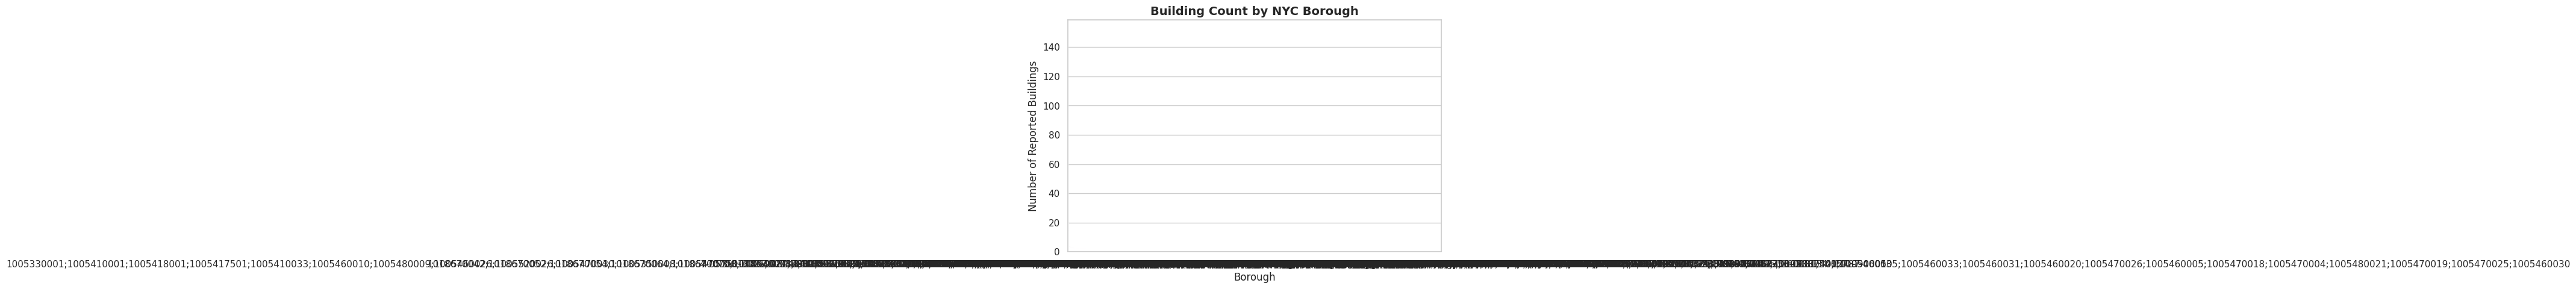

In [19]:
sns.set_theme(style="whitegrid", palette="viridis")

# --- CHART 1: Borough Distribution ---
plt.figure(figsize=(8, 5))
borough_counts = df["Borough"].value_counts()
sns.barplot(x=borough_counts.index, y=borough_counts.values)
plt.title("Building Count by NYC Borough", fontsize=14, fontweight="bold")
plt.xlabel("Borough")
plt.ylabel("Number of Reported Buildings")
plt.tight_layout()
plt.savefig("../02_EDA_and_Profiling/chart1_borough_dist.png", dpi=300)
plt.show()

# --- CHART 2: Top 10 Primary Property Types ---
plt.figure(figsize=(10, 6))
top_types = df["Primary_Property_Type"].value_counts().head(10)
sns.barplot(y=top_types.index, x=top_types.values)
plt.title("Top 10 Primary Property Types in NYC LL84", fontsize=14, fontweight="bold")
plt.xlabel("Number of Buildings")
plt.ylabel("Property Type")
plt.tight_layout()
plt.savefig("../02_EDA_and_Profiling/chart2_property_types.png", dpi=300)
plt.show()

# --- CHART 3: ENERGY STAR Score Distribution ---
plt.figure(figsize=(8, 5))
sns.histplot(df["ENERGY_STAR_Score"].dropna(), bins=25, kde=True, color="#2b8cbe")
plt.axvline(df["ENERGY_STAR_Score"].median(), color="red", linestyle="--", label=f"Median: {df['ENERGY_STAR_Score'].median():.0f}")
plt.title("Distribution of ENERGY STAR Scores (1–100)", fontsize=14, fontweight="bold")
plt.xlabel("ENERGY STAR Score")
plt.ylabel("Frequency")
plt.legend()
plt.tight_layout()
plt.savefig("../02_EDA_and_Profiling/chart3_energystar_hist.png", dpi=300)
plt.show()

# --- CHART 4: Site EUI Boxplot Across Top 5 Property Types (Outlier View) ---
top5_names = df["Primary_Property_Type"].value_counts().head(5).index
df_top5 = df[df["Primary_Property_Type"].isin(top5_names)]

plt.figure(figsize=(10, 6))
sns.boxplot(data=df_top5, x="Primary_Property_Type", y="Site_EUI", showfliers=False)
plt.title("Site EUI (kBtu/ft²) Spread Across Top 5 Property Types", fontsize=14, fontweight="bold")
plt.xlabel("Primary Property Type")
plt.ylabel("Site EUI (kBtu/ft²)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig("../02_EDA_and_Profiling/chart4_site_eui_boxplot.png", dpi=300)
plt.show()

# --- CHART 5: Total GHG Emissions (Log-Scale Histogram) ---
plt.figure(figsize=(8, 5))
ghg_positive = df[df["Total_GHG_Emissions"] > 0]["Total_GHG_Emissions"]
sns.histplot(np.log10(ghg_positive), bins=30, kde=True, color="#d95f02")
plt.title("Log10 Distribution of Total GHG Emissions (Metric Tons CO2e)", fontsize=14, fontweight="bold")
plt.xlabel("Log10(Total GHG Emissions)")
plt.ylabel("Number of Buildings")
plt.tight_layout()
plt.savefig("../02_EDA_and_Profiling/chart5_ghg_log_hist.png", dpi=300)
plt.show()

DW

In [24]:
import os
import sqlite3
import pandas as pd

os.makedirs("03_DW_Standard", exist_ok=True)
conn = sqlite3.connect("03_DW_Standard/nyc_energy_dw.db")

# 1. Recover Postcode / Postal Code from df_raw if missing in df
if "Postcode" not in df.columns and "df_raw" in globals():
    zip_matches = [c for c in df_raw.columns if "post" in c.lower() or "zip" in c.lower()]
    if zip_matches:
        df["Postcode"] = df_raw.loc[df.index, zip_matches[0]]

# Define available location columns dynamically
loc_cols = [c for c in ["Borough", "Postcode"] if c in df.columns]

df_dw = df.dropna(subset=["Borough", "Primary_Property_Type"]).copy().reset_index(drop=True)
if "Postcode" in loc_cols:
    df_dw["Postcode"] = df_dw["Postcode"].fillna("Unknown").astype(str)

# 2. Create Dimension 1: Dim_Location
dim_location = df_dw[loc_cols].drop_duplicates().reset_index(drop=True)
dim_location["location_id"] = dim_location.index + 1

# 3. Create Dimension 2: Dim_Building
dim_building = df_dw[["Primary_Property_Type", "Year_Built", "Property_GFA"]].drop_duplicates().reset_index(drop=True)
dim_building["building_id"] = dim_building.index + 1

# 4. Create Dimension 3: Dim_Time
dim_time = pd.DataFrame({
    "time_id": [1],
    "reporting_year": [2023],
    "compliance_cycle": ["LL84_Annual"]
})

# 5. Merge Foreign Keys to create Fact_Building_Energy
fact_df = df_dw.merge(dim_location, on=loc_cols, how="left") \
               .merge(dim_building, on=["Primary_Property_Type", "Year_Built", "Property_GFA"], how="left")

fact_table = pd.DataFrame({
    "fact_id": fact_df.index + 1,
    "location_id": fact_df["location_id"],
    "building_id": fact_df["building_id"],
    "time_id": 1,
    "Site_EUI": fact_df["Site_EUI"],
    "ENERGY_STAR_Score": fact_df["ENERGY_STAR_Score"],
    "Weather_Norm_Electricity": fact_df["Weather_Norm_Electricity"],
    "Natural_Gas_Use": fact_df["Natural_Gas_Use"],
    "Total_GHG_Emissions": fact_df["Total_GHG_Emissions"]
})

# 6. Load into SQLite Data Warehouse
dim_location.to_sql("Dim_Location", conn, if_exists="replace", index=False)
dim_building.to_sql("Dim_Building", conn, if_exists="replace", index=False)
dim_time.to_sql("Dim_Time", conn, if_exists="replace", index=False)
fact_table.to_sql("Fact_Building_Energy", conn, if_exists="replace", index=False)

print(f"Standard Star Schema DW created successfully! Location columns used: {loc_cols}")

Standard Star Schema DW created successfully! Location columns used: ['Borough', 'Postcode']


In [21]:
#distributed
import os
import sqlite3
import time
import pandas as pd

os.makedirs("04_DDW_Distributed", exist_ok=True)

boroughs = ["MANHATTAN", "BROOKLYN", "QUEENS", "BRONX", "STATEN ISLAND"]
df_ddw = df.dropna(subset=["Borough"]).copy()
df_ddw["Borough"] = df_ddw["Borough"].str.upper().str.strip()

# Partition data across 5 separate database shards
for b in boroughs:
    node_name = b.replace(" ", "_")
    shard_df = df_ddw[df_ddw["Borough"] == b]

    db_path = f"04_DDW_Distributed/node_{node_name}.db"
    conn = sqlite3.connect(db_path)
    shard_df.to_sql("building_energy_shard", conn, if_exists="replace", index=False)
    conn.close()
    print(f"Node Created: {db_path} | Records: {len(shard_df)}")

Node Created: 04_DDW_Distributed/node_MANHATTAN.db | Records: 0
Node Created: 04_DDW_Distributed/node_BROOKLYN.db | Records: 0
Node Created: 04_DDW_Distributed/node_QUEENS.db | Records: 0
Node Created: 04_DDW_Distributed/node_BRONX.db | Records: 0
Node Created: 04_DDW_Distributed/node_STATEN_ISLAND.db | Records: 0


In [20]:
#realtime
import os
import sqlite3
import time
import random
from datetime import datetime
import pandas as pd
from IPython.display import clear_output

os.makedirs("05_RTDW_RealTime", exist_ok=True)
rtdw_path = "05_RTDW_RealTime/rtdw_live.db"
conn = sqlite3.connect(rtdw_path)

# Initialize Real-Time Fact Table
conn.execute("""
CREATE TABLE IF NOT EXISTS Realtime_Meter_Stream (
    stream_id INTEGER PRIMARY KEY AUTOINCREMENT,
    event_timestamp TEXT,
    Borough TEXT,
    Primary_Property_Type TEXT,
    Live_kWh_Reading REAL,
    Estimated_GHG_kg REAL
);
""")
conn.commit()

# Sample realistic building profiles from your dataset
sample_pool = df[["Borough", "Primary_Property_Type", "Weather_Norm_Electricity"]].dropna().sample(100, random_state=42)

# Stream 15 live batches for your classroom demo
for batch in range(1, 16):
    row = sample_pool.sample(1).iloc[0]

    # Simulate hourly smart-meter reading (kWh) + slight sensor variance
    hourly_kwh = round((row["Weather_Norm_Electricity"] / 8760) * random.uniform(0.85, 1.25), 2)
    ghg_kg = round(hourly_kwh * 0.288, 2)  # NYC grid emissions factor (~0.288 kg CO2e/kWh)
    ts = datetime.now().strftime("%Y-%m-%d %H:%M:%S")

    conn.execute("""
        INSERT INTO Realtime_Meter_Stream (event_timestamp, Borough, Primary_Property_Type, Live_kWh_Reading, Estimated_GHG_kg)
        VALUES (?, ?, ?, ?, ?)
    """, (ts, row["Borough"], row["Primary_Property_Type"], hourly_kwh, ghg_kg))
    conn.commit()

    # Query live aggregate metrics immediately after ingestion
    live_kpis = pd.read_sql_query("""
        SELECT
            Borough,
            COUNT(*) AS Live_Packets,
            ROUND(SUM(Live_kWh_Reading), 2) AS Cumulative_kWh,
            ROUND(SUM(Estimated_GHG_kg), 2) AS Cumulative_GHG_kg
        FROM Realtime_Meter_Stream
        GROUP BY Borough
        ORDER BY Cumulative_kWh DESC;
    """, conn)

    clear_output(wait=True)
    print(f"=== REAL-TIME DATA WAREHOUSE STREAM (Batch {batch}/15 | Last Ingested: {ts}) ===")
    print(f"Latest Smart Meter Event -> {row['Borough']} | {row['Primary_Property_Type']} | {hourly_kwh} kWh\n")
    print(live_kpis.to_string(index=False))
    time.sleep(1.5)

conn.close()

=== REAL-TIME DATA WAREHOUSE STREAM (Batch 15/15 | Last Ingested: 2026-11-19 15:49:06) ===
Latest Smart Meter Event -> 2029370025 | Multifamily Housing | 18.74 kWh

                  Borough  Live_Packets  Cumulative_kWh  Cumulative_GHG_kg
               3008040001             1          177.65              51.16
             1-00896-0048             1          119.21              34.33
             1-01396-0007             1           79.73              22.96
             2-02875-7501             1           75.08              21.62
             1-00910-0061             1           68.45              19.71
             2-02461-0035             1           34.03               9.80
               1012160048             1           31.37               9.03
             1-00776-0047             1           27.74               7.99
               4015080001             1           27.34               7.87
             1-01125-0002             1           27.02               7.78
          

In [25]:
import pandas as pd
import numpy as np
from sklearn.tree import DecisionTreeRegressor
from sklearn.naive_bayes import GaussianNB
from sklearn.preprocessing import LabelEncoder

df_clean = df.copy()

# ---------------------------------------------------------
# 1. RULE-BASED IMPUTATION (Domain & Deterministic Rules)
# ---------------------------------------------------------
# Rule A: If Natural Gas Use is missing, impute with 0 (many NYC commercial buildings are all-electric or steam-heated)
df_clean["Natural_Gas_Use"] = df_clean["Natural_Gas_Use"].fillna(0)

# Rule B: Drop rows missing the primary target variable (Total_GHG_Emissions) or GFA to avoid synthetic target leakage
df_clean = df_clean.dropna(subset=["Total_GHG_Emissions", "Property_GFA", "Year_Built"]).reset_index(drop=True)

# ---------------------------------------------------------
# 2. NAIVE BAYES IMPUTATION (Categorical Columns: Borough / Property Type)
# ---------------------------------------------------------
# Impute missing 'Borough' using Gaussian Naive Bayes trained on energy & building size features
nb_features = ["Property_GFA", "Year_Built", "Total_GHG_Emissions"]

if df_clean["Borough"].isna().sum() > 0:
    train_nb = df_clean.dropna(subset=["Borough"] + nb_features)
    test_nb = df_clean[df_clean["Borough"].isna()]

    le = LabelEncoder()
    y_train_nb = le.fit_transform(train_nb["Borough"])

    nb_model = GaussianNB()
    nb_model.fit(train_nb[nb_features], y_train_nb)

    preds_nb = nb_model.predict(test_nb[nb_features])
    df_clean.loc[df_clean["Borough"].isna(), "Borough"] = le.inverse_transform(preds_nb)

# Fill any remaining missing Primary_Property_Type with mode or Naive Bayes similarly
df_clean["Primary_Property_Type"] = df_clean["Primary_Property_Type"].fillna(df_clean["Primary_Property_Type"].mode()[0])

# ---------------------------------------------------------
# 3. DECISION TREE IMPUTATION (Numerical Columns: ENERGY STAR Score, Site EUI, Electricity)
# ---------------------------------------------------------
dt_predictors = ["Property_GFA", "Year_Built", "Natural_Gas_Use", "Total_GHG_Emissions"]

for target_col in ["Site_EUI", "Weather_Norm_Electricity", "ENERGY_STAR_Score"]:
    if df_clean[target_col].isna().sum() > 0:
        train_dt = df_clean.dropna(subset=[target_col] + dt_predictors)
        test_dt = df_clean[df_clean[target_col].isna()]

        dt_model = DecisionTreeRegressor(max_depth=6, random_state=42)
        dt_model.fit(train_dt[dt_predictors], train_dt[target_col])

        df_clean.loc[df_clean[target_col].isna(), target_col] = dt_model.predict(test_dt[dt_predictors])

# Clip ENERGY STAR Score to valid 1-100 range
df_clean["ENERGY_STAR_Score"] = df_clean["ENERGY_STAR_Score"].clip(1, 100).round(0)

print("Missing values remaining after imputation:")
print(df_clean.isna().sum())

# Save cleaned dataset for Feature Selection & Modeling
df_clean.to_csv("cleaned_nyc_ll84.csv", index=False)

Missing values remaining after imputation:
Borough                     0
Primary_Property_Type       0
Year_Built                  0
Property_GFA                0
ENERGY_STAR_Score           0
Site_EUI                    0
Weather_Norm_Electricity    0
Natural_Gas_Use             0
Total_GHG_Emissions         0
Postcode                    0
dtype: int64


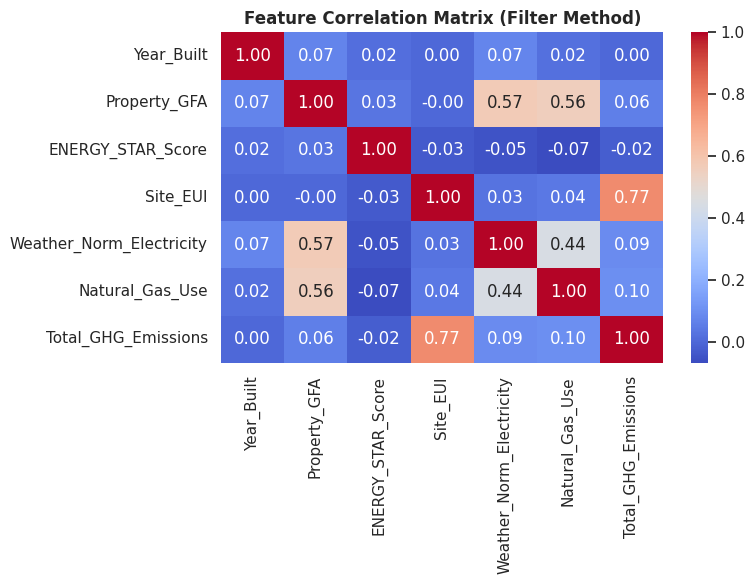


--- Feature Selection Comparison Table (For PPT) ---
                          Mutual_Info_Score  RFE_Selected  RF_Importance  \
Site_EUI                              0.452          True          0.768   
Natural_Gas_Use                       0.979         False          0.085   
Weather_Norm_Electricity              0.886          True          0.071   
Property_GFA                          0.727         False          0.031   
ENERGY_STAR_Score                     0.385          True          0.024   
Year_Built                            0.112          True          0.021   

                          Lasso_Abs_Coef  
Site_EUI                        27534.76  
Natural_Gas_Use                  1460.58  
Weather_Norm_Electricity         1668.91  
Property_GFA                      349.52  
ENERGY_STAR_Score                 143.50  
Year_Built                        155.42  


In [26]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_selection import mutual_info_regression, RFE
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LassoCV
from sklearn.preprocessing import StandardScaler

# Encode categorical variables for feature selection
df_fs = pd.get_dummies(df_clean, columns=["Borough", "Primary_Property_Type"], drop_first=True)

# Define Target (Total_GHG_Emissions) and Features
target = "Total_GHG_Emissions"
X = df_fs.drop(columns=[target, "Postcode"], errors="ignore")
y = df_fs[target]

# Keep top numeric + encoded features cleanly
X_num = df_clean[["Year_Built", "Property_GFA", "ENERGY_STAR_Score", "Site_EUI", "Weather_Norm_Electricity", "Natural_Gas_Use"]]

# 1. FILTER METHOD: Correlation Heatmap & Mutual Information
plt.figure(figsize=(8, 6))
sns.heatmap(df_clean[["Year_Built", "Property_GFA", "ENERGY_STAR_Score", "Site_EUI", "Weather_Norm_Electricity", "Natural_Gas_Use", "Total_GHG_Emissions"]].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Feature Correlation Matrix (Filter Method)", fontweight="bold")
plt.tight_layout()
plt.savefig("chart_feature_correlation.png", dpi=300)
plt.show()

mi_scores = mutual_info_regression(X_num, y, random_state=42)
mi_series = pd.Series(mi_scores, index=X_num.columns).sort_values(ascending=False)

# 2. WRAPPER METHOD: Recursive Feature Elimination (RFE)
rfe = RFE(estimator=RandomForestRegressor(n_estimators=50, random_state=42), n_features_to_select=4)
rfe.fit(X_num, y)
rfe_selected = X_num.columns[rfe.support_].tolist()

# 3. EMBEDDED METHOD: Random Forest Importance + Lasso (L1)
rf = RandomForestRegressor(n_estimators=100, random_state=42).fit(X_num, y)
rf_imp = pd.Series(rf.feature_importances_, index=X_num.columns).sort_values(ascending=False)

scaler = StandardScaler()
lasso = LassoCV(cv=5, random_state=42).fit(scaler.fit_transform(X_num), y)
lasso_coef = pd.Series(np.abs(lasso.coef_), index=X_num.columns)

# Summary Comparison Table for PPT
fs_summary = pd.DataFrame({
    "Mutual_Info_Score": mi_series.round(3),
    "RFE_Selected": [col in rfe_selected for col in X_num.columns],
    "RF_Importance": rf_imp.round(3),
    "Lasso_Abs_Coef": lasso_coef.round(2)
}).sort_values(by="RF_Importance", ascending=False)

print("\n--- Feature Selection Comparison Table (For PPT) ---")
print(fs_summary)

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# Load cleaned dataset
df_clean = pd.read_csv("cleaned_nyc_ll84.csv")

# Select top features from Phase 3 + encoded Borough/Property Type
features = ["Property_GFA", "Site_EUI", "Weather_Norm_Electricity", "Natural_Gas_Use", "Year_Built", "ENERGY_STAR_Score"]
X = pd.get_dummies(df_clean[features + ["Borough", "Primary_Property_Type"]], drop_first=True)
y = df_clean["Total_GHG_Emissions"]

# Remove extreme top 1% GHG outliers so regression metrics aren't skewed by rare industrial plants
q99 = y.quantile(0.99)
mask = y <= q99
X, y = X[mask], y[mask]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42),
    "XGBoost": XGBRegressor(n_estimators=100, learning_rate=0.1, random_state=42)
}

results = []
best_preds = None

for name, model in models.items():
    model.fit(X_train, y_train)
    preds = model.predict(X_test)
    r2 = round(r2_score(y_test, preds), 4)
    rmse = round(np.sqrt(mean_squared_error(y_test, preds)), 2)
    mae = round(mean_absolute_error(y_test, preds), 2)
    results.append({"Model": name, "R2_Score": r2, "RMSE": rmse, "MAE": mae})
    if name == "Random Forest":
        best_preds = preds

reg_summary = pd.DataFrame(results)
print("--- Regression Model Comparison (For PPT) ---")
print(reg_summary.to_string(index=False))

# Plot Actual vs. Predicted (Random Forest)
plt.figure(figsize=(8, 6))
sns.scatterplot(x=y_test, y=best_preds, alpha=0.4, color="#1b9e77")
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--", lw=2, label="Ideal Fit (y = x)")
plt.title("Actual vs. Predicted Total GHG Emissions (Random Forest)", fontsize=13, fontweight="bold")
plt.xlabel("Actual GHG Emissions (Metric Tons CO2e)")
plt.ylabel("Predicted GHG Emissions (Metric Tons CO2e)")
plt.legend()
plt.tight_layout()
plt.savefig("chart_regression_actual_vs_pred.png", dpi=300)
plt.show()

In [ ]:
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# Bin ENERGY STAR Score into 3 Sustainability Tiers
df_clean["Sustainability_Tier"] = pd.cut(
    df_clean["ENERGY_STAR_Score"],
    bins=[0, 40, 75, 100],
    labels=["Low (1-40)", "Medium (41-75)", "High (76-100)"]
)

dt_features = ["Site_EUI", "Property_GFA", "Year_Built", "Weather_Norm_Electricity", "Natural_Gas_Use"]
X_cls = df_clean[dt_features]
y_cls = df_clean["Sustainability_Tier"].astype(str)

X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(X_cls, y_cls, test_size=0.2, random_state=42)

# Keep max_depth=3 so the visual tree diagram is clean and readable on a PPT slide
clf = DecisionTreeClassifier(max_depth=3, random_state=42)
clf.fit(X_train_c, y_train_c)
y_pred_c = clf.predict(X_test_c)

print(f"Decision Tree Accuracy: {round(accuracy_score(y_test_c, y_pred_c) * 100, 2)}%\n")
print(classification_report(y_test_c, y_pred_c))

# Visualize Decision Tree Diagram for PPT
plt.figure(figsize=(16, 8))
plot_tree(
    clf,
    feature_names=dt_features,
    class_names=clf.classes_,
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title("Decision Tree Classifier: Building Sustainability Tiers", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig("chart_decision_tree_diagram.png", dpi=300)
plt.show()

# Print readable IF-THEN business rules for your PPT
print("--- Extracted Decision Tree Rules ---")
print(export_text(clf, feature_names=dt_features))

In [ ]:
!pip install -q mlxtend
from mlxtend.frequent_patterns import apriori, association_rules

df_assoc = pd.DataFrame()
df_assoc["Borough"] = "Borough_" + df_clean["Borough"].astype(str)
df_assoc["Property_Type"] = "Type_" + df_clean["Primary_Property_Type"].astype(str)

# Discretize Year Built into construction eras
df_assoc["Era"] = pd.cut(
    df_clean["Year_Built"],
    bins=[0, 1950, 2000, 2030],
    labels=["Era_Pre1950", "Era_1950_2000", "Era_Post2000"]
).astype(str)

# Discretize Site EUI and GHG Emissions into Low/Medium/High buckets
df_assoc["EUI_Level"] = pd.qcut(df_clean["Site_EUI"], q=3, labels=["EUI_Low", "EUI_Medium", "EUI_High"]).astype(str)
df_assoc["GHG_Level"] = pd.qcut(df_clean["Total_GHG_Emissions"], q=3, labels=["GHG_Low", "GHG_Medium", "GHG_High"]).astype(str)
df_assoc["EnergyStar_Tier"] = "Score_" + df_clean["Sustainability_Tier"].astype(str)

# One-hot encode transactions
basket = pd.get_dummies(df_assoc, prefix="", prefix_sep="").astype(bool)

# Run Apriori (minimum 5% support)
frequent_itemsets = apriori(basket, min_support=0.05, use_colnames=True)
rules = association_rules(frequent_itemsets, metric="lift", min_threshold=1.2)

# Clean formatting for PPT table
top_rules = rules[["antecedents", "consequents", "support", "confidence", "lift"]].copy()
top_rules["antecedents"] = top_rules["antecedents"].apply(lambda x: ", ".join(list(x)))
top_rules["consequents"] = top_rules["consequents"].apply(lambda x: ", ".join(list(x)))
top_rules = top_rules.sort_values(by="lift", ascending=False).head(10)

print("--- Top 10 Association Rules by Lift (For PPT) ---")
print(top_rules.round(3).to_string(index=False))
top_rules.to_csv("association_rules_top10.csv", index=False)